In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the datasets
df_movies = pd.read_csv('ml-1m/movies.dat', sep='::', engine='python', header=None,
                        names=['MovieID', 'Title', 'Genres'], encoding="latin-1")
df_ratings = pd.read_csv('ml-1m/ratings.dat', sep='::', engine='python', header=None,
                         names=['UserID', 'MovieID', 'Rating', 'Timestamp'], encoding="latin-1")
df_users = pd.read_csv('ml-1m/users.dat', sep='::', engine='python', header=None,
                       names=['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code'], encoding="latin-1")

In [2]:
print(df_movies.head())
print(df_ratings.head())
print(df_users.head())

   MovieID                               Title                        Genres
0        1                    Toy Story (1995)   Animation|Children's|Comedy
1        2                      Jumanji (1995)  Adventure|Children's|Fantasy
2        3             Grumpier Old Men (1995)                Comedy|Romance
3        4            Waiting to Exhale (1995)                  Comedy|Drama
4        5  Father of the Bride Part II (1995)                        Comedy
   UserID  MovieID  Rating  Timestamp
0       1     1193       5  978300760
1       1      661       3  978302109
2       1      914       3  978301968
3       1     3408       4  978300275
4       1     2355       5  978824291
   UserID Gender  Age  Occupation Zip-code
0       1      F    1          10    48067
1       2      M   56          16    70072
2       3      M   25          15    55117
3       4      M   45           7    02460
4       5      M   25          20    55455


In [78]:
# The data loaded and characterized: users, items, interactions, density;
users = len(set(df_users['UserID'].dropna())) # filter out just in case dublicated and nulls
movies = len(set(df_movies['MovieID'].dropna())) # filter out just in case dublicated and nulls
ratings = len(df_ratings)

users_ratingDf = df_ratings["UserID"].nunique()
movies_ratingDf = df_ratings["MovieID"].nunique()

print('All users:', users)
print("Users in ratings dataset:", users_ratingDf)

print('All movies (items):', movies)
print("Movies in ratings dataset:", movies_ratingDf)
print('Proportion of rated movies', movies_ratingDf / movies)

# Density = what proportion of all possible interactions has actually happened
print("Number of ratings (interactions):", ratings)
density = ratings / (users * movies)
print('Density', density)

All users: 6040
Users in ratings dataset: 6040
All movies (items): 3883
Movies in ratings dataset: 3706
Proportion of rated movies 0.9544166881277363
Number of ratings (interactions): 1000209
Density 0.04264679797998748


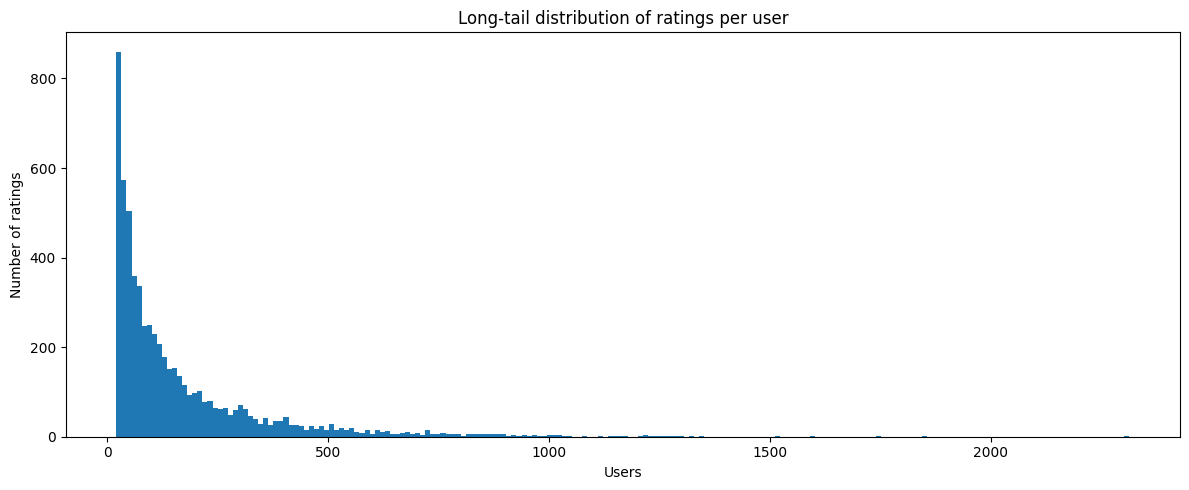

In [4]:
# Long-tail distribution of interactions per user
interactions_users = df_ratings["UserID"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
plt.hist(interactions_users, bins=200)
plt.xlabel("Users")
plt.ylabel("Number of ratings")
plt.title("Long-tail distribution of ratings per user")

plt.tight_layout()
plt.show()

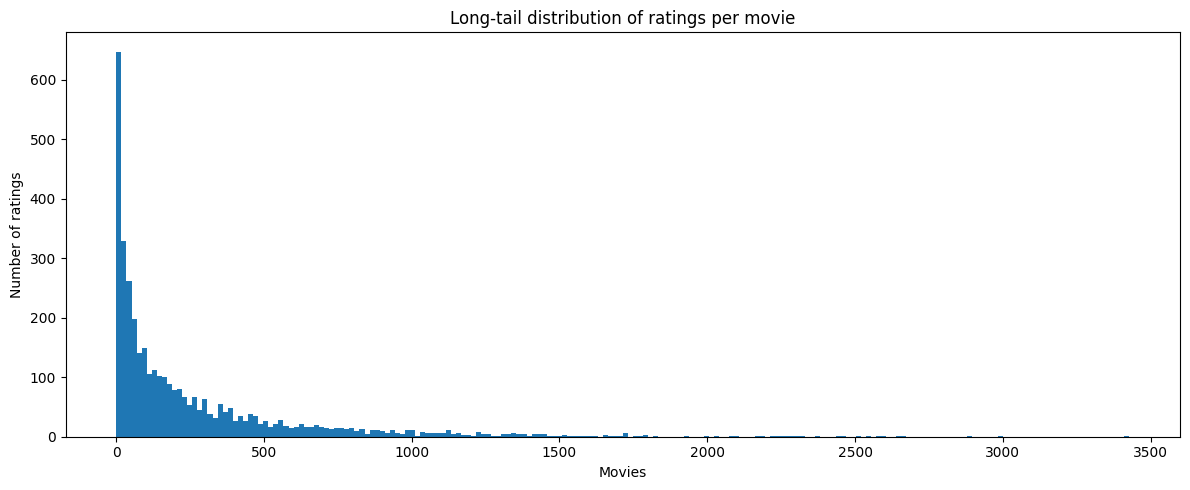

In [5]:
# Long-tail distribution of ratings per movie
interactions_movies = df_ratings["MovieID"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
plt.hist(interactions_movies, bins=200)
plt.xlabel("Movies")
plt.ylabel("Number of ratings")
plt.title("Long-tail distribution of ratings per movie")
plt.tight_layout()
plt.show()

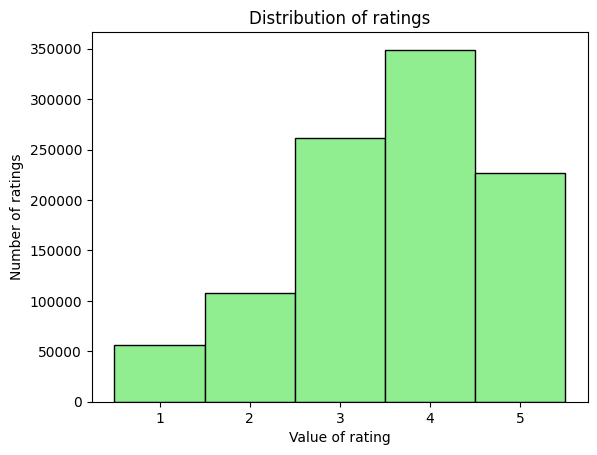

In [6]:
# the rating distribution;
rating_values = df_ratings['Rating']
plt.hist(rating_values.tolist(), bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
         edgecolor='black', color='lightgreen')
plt.xlabel("Value of rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of ratings")
plt.show()

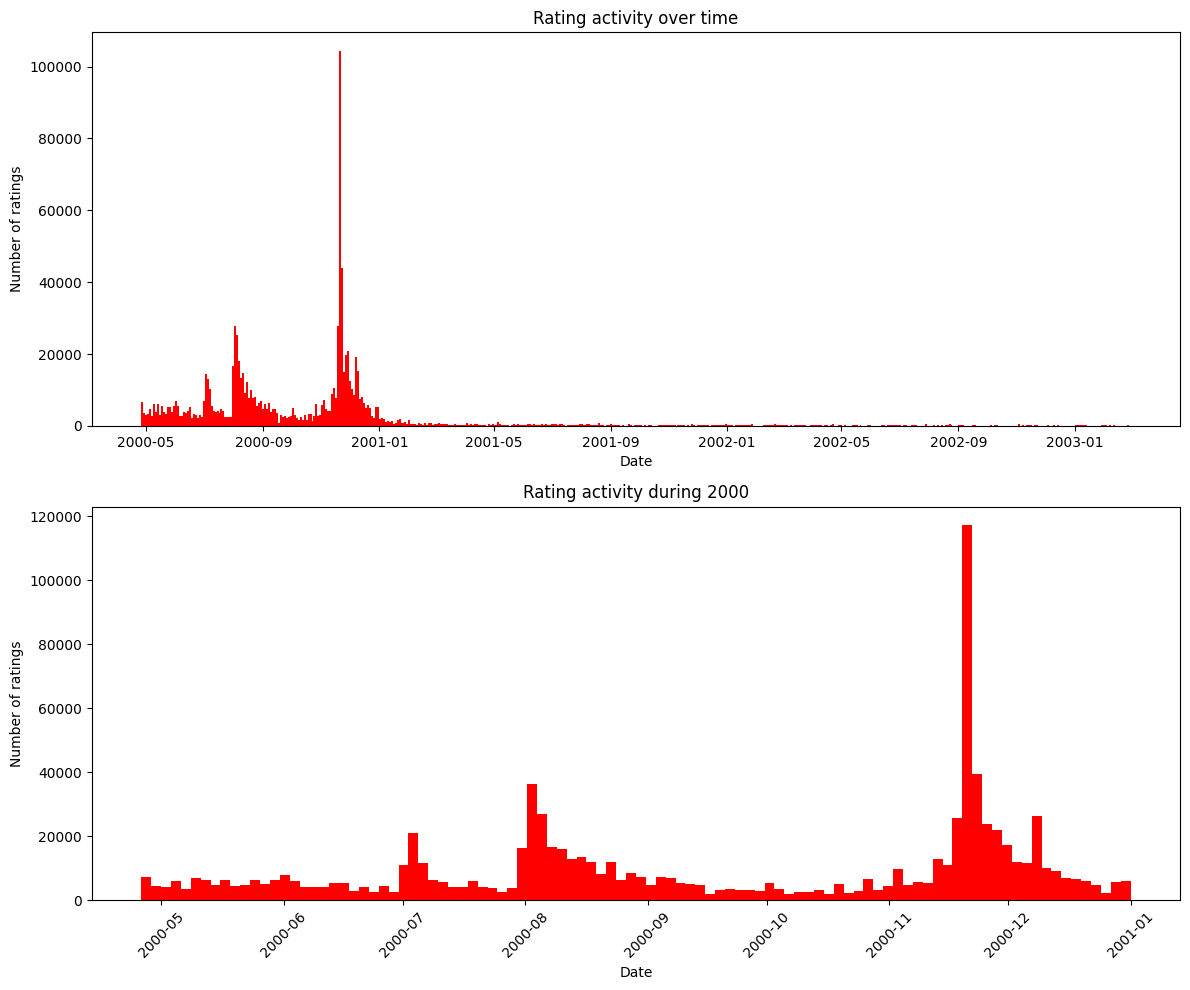

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
# the time span and how activity is distributed across it.
timestamps = pd.to_datetime(df_ratings['Timestamp'], unit='s')

ax1.hist(timestamps.tolist(), bins=500, color='red')
ax1.set_xlabel("Date")
ax1.set_ylabel("Number of ratings")
ax1.set_title("Rating activity over time")
plt.xticks(rotation=45)

timestamps_2000 = timestamps[
    (timestamps >= '2000-01-01') &
    (timestamps < '2001-01-01')
]

ax2.hist(timestamps_2000, bins=100, color='red')
ax2.set_xlabel("Date")
ax2.set_ylabel("Number of ratings")
ax2.set_title("Rating activity during 2000")
plt.tight_layout()
plt.show()

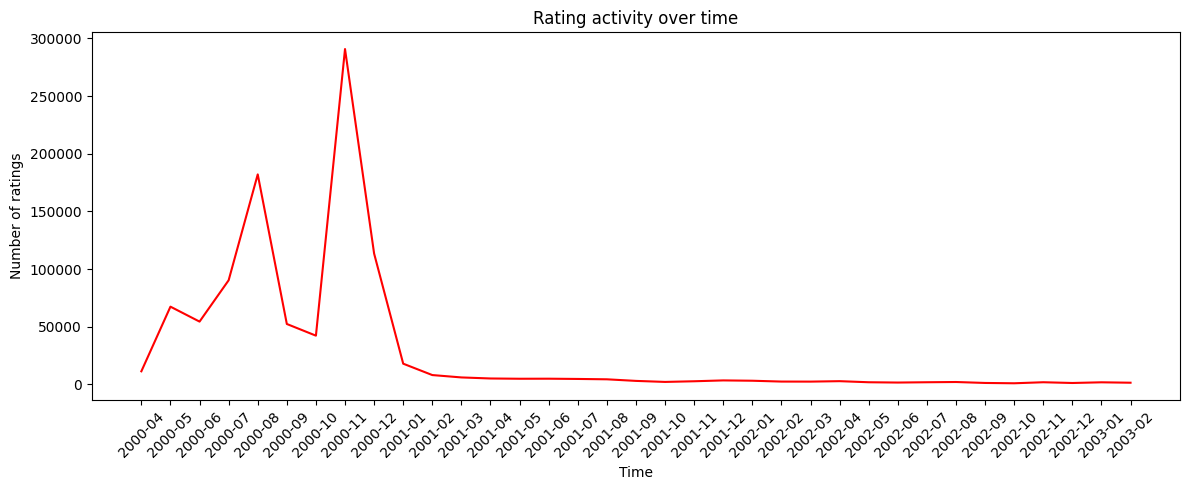

In [8]:
ratings_per_month = timestamps.dt.to_period('M').value_counts().sort_index()
plt.figure(figsize=(12, 5))
plt.plot(ratings_per_month.index.astype(str), ratings_per_month.values, color='red')
plt.xlabel("Time")
plt.ylabel("Number of ratings")
plt.title("Rating activity over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
# If you filter out low-activity users or items, state the threshold and how many rows it removed.

# Check that all ratings are on scale 1 to 5
rating_scale = df_ratings["Rating"]
print("Minimum rating:", rating_scale.min())
print("Maximum rating:", rating_scale.max())

# Check that all users have at least 20 ratings
usercount = df_ratings["UserID"].value_counts().sort_values(ascending=True)
print(usercount.head(3))

# Filter out movies with less than 5 ratings
movie_counts = df_ratings["MovieID"].value_counts()
filtered_ratings = df_ratings[df_ratings["MovieID"].isin(movie_counts[movie_counts >= 5].index)]

# Calculate new ratings per user after deleting movies
new_usercount = filtered_ratings["UserID"].value_counts().sort_values(ascending=True)

print("\nAfter filtering")
print("Ratings:", len(filtered_ratings))
print("Rows removed:", ratings-len(filtered_ratings))
print("Users:", filtered_ratings["UserID"].nunique())
print("Movies:", filtered_ratings["MovieID"].nunique())
print("Number of filtered movies", movies_ratingDf-filtered_ratings["MovieID"].nunique())
print("\nUpdated user counts:", new_usercount.head(6))

Minimum rating: 1
Maximum rating: 5
UserID
4775    20
2714    20
160     20
Name: count, dtype: int64

After filtering
Ratings: 999611
Rows removed: 598
Users: 6040
Movies: 3416
Number of filtered movies 290

Updated user counts: UserID
1713    18
5258    19
2530    19
4628    19
2930    19
1406    20
Name: count, dtype: int64


In [75]:
# Now on the (filtered) data used is
ratings_df = filtered_ratings
print(ratings_df.head())

   UserID  MovieID  Rating  Timestamp
0       1     1193       5  978300760
1       1      661       3  978302109
2       1      914       3  978301968
3       1     3408       4  978300275
4       1     2355       5  978824291


In [94]:
# Exact timestamps computed

# TO DO: modifications on cutoff_date
trainDate = "2000-11-22"
split70 = "2000-11-23"
validationDate = "2000-12-31"
split90 = "2001-01-01"
cutoff_date = split70
cutoff_timestamp = pd.Timestamp(cutoff_date).timestamp()

# Ratings before cutoff
ratings_before = ratings_df[ratings_df["Timestamp"] < cutoff_timestamp]

# Rating counts and percentage
ratings_before_count = len(ratings_before)
total_ratings = len(ratings_df)
rating_percentage = ratings_before_count / total_ratings * 100

# user counts and percentage
total_users = ratings_df["UserID"].nunique()
users_before_count = ratings_before["UserID"].nunique()
user_percentage = users_before_count / total_users * 100

print("Ratings before cutoff:", ratings_before_count)
print(f"Percentage of ratings before cutoff: {rating_percentage:.2f}%")

print("Unique users before cutoff:", users_before_count)
print(f"Percentage of users before cutoff: {user_percentage:.2f}%")

Ratings before cutoff: 716096
Percentage of ratings before cutoff: 71.64%
Unique users before cutoff: 4952
Percentage of users before cutoff: 81.99%


In [101]:
# split into train 70% / validation 20% / test 10%

cutoff_dateTrain = "2000-11-23"
cutoff_dateTest = "2001-01-01"
cutoff_train = pd.Timestamp(cutoff_dateTrain).timestamp()
cutoff_test = pd.Timestamp(cutoff_dateTest).timestamp()

training_set = ratings_df[ratings_df["Timestamp"] < cutoff_train]
print(len(training_set))

validation_set = ratings_df[(ratings_df["Timestamp"] >= cutoff_train) & (ratings_df["Timestamp"] < cutoff_test)]
print(len(validation_set))

test_set = ratings_df[ratings_df["Timestamp"] >= cutoff_test]
print(len(test_set))

716096
188176
95339
